
# Exercice 1 — Estimateur de Bayes et risque de Bayes

## Question 1 (M) : le cadre choisi

En cours les exemples portaient surtout sur des variables binaires ou sur le modèle linéaire gaussien. La consigne demande un cadre différent au niveau des espaces $\mathcal{X}$ et $\mathcal{Y}$, alors je pars sur un petit problème physique : prédire la puissance électrique d'une éolienne domestique à partir de la vitesse du vent.

* $\mathcal{X} = [3, 12]$ : la vitesse du vent $v$, en m/s. En dessous de 3 m/s l'éolienne ne démarre pas, et vers 12 m/s elle atteint son régime nominal, d'où cet intervalle.
* $\mathcal{Y} = \mathbb{R}$ : la puissance produite $P$, en kW.
* Loi jointe : $X \sim \mathcal{U}([3,12])$ et
$$Y = c\,X^{3} + \varepsilon, \qquad c = 0.3 \ \text{kW}\cdot\text{s}^{3}\cdot\text{m}^{-3},
\qquad \varepsilon \sim \mathcal{N}(0,\sigma^{2}),
\quad \varepsilon \perp X, \quad \sigma = 15 \text{ kW}.$$
La puissance d'une éolienne varie en gros comme le cube de la vitesse du vent (l'énergie cinétique qui traverse les pales croît en $v^3$), ce qui justifie le terme $c\,v^3$, le coefficient $c$ portant l'unité qui rend le produit homogène à des kW. Le bruit $\varepsilon$ absorbe tout le reste : turbulence, densité de l'air, orientation de la machine, usure. Le modèle gaussien non tronqué est une approximation : près de la vitesse de démarrage, la puissance moyenne ($c \cdot 3^3 \approx 8$ kW) est petite devant $\sigma = 15$ kW et la loi autorise des puissances négatives, physiquement impossibles. On l'accepte car cela ne change rien aux calculs qui suivent, mais un bruit dont l'amplitude croît avec le vent serait plus réaliste.
* Perte : quadratique, $\ell(y,z) = (y-z)^2$.

### Prédicteur de Bayes

On note $\mu(x) = \mathbb{E}[Y \mid X = x]$ et on veut minimiser $R(f) = \mathbb{E}[(Y - f(X))^2]$. L'astuce habituelle consiste à faire apparaître $\mu(X)$ dans le carré, puis à développer :
$$
\begin{aligned}
R(f) &= \mathbb{E}\big[(Y - \mu(X) + \mu(X) - f(X))^{2}\big]\\
&= \mathbb{E}\big[(Y-\mu(X))^{2}\big] + \mathbb{E}\big[(\mu(X)-f(X))^{2}\big]
 + 2\,\mathbb{E}\big[(Y-\mu(X))(\mu(X)-f(X))\big].
\end{aligned}
$$
Le terme croisé disparaît : en conditionnant par $X$, le facteur $\mu(X)-f(X)$ sort de l'espérance et il reste $\mathbb{E}[Y-\mu(X)\mid X] = 0$,
$$\mathbb{E}\big[(Y-\mu(X))(\mu(X)-f(X))\big]
= \mathbb{E}\big[(\mu(X)-f(X))\,\mathbb{E}[Y-\mu(X)\mid X]\big] = 0.$$
Il ne reste donc que deux termes positifs, dont le premier ne dépend pas de $f$ :
$$R(f) = \mathbb{E}\big[(Y-\mu(X))^{2}\big] + \mathbb{E}\big[(\mu(X)-f(X))^{2}\big]
\ \ge\ \mathbb{E}\big[(Y-\mu(X))^{2}\big].$$
L'inégalité est une égalité si et seulement si le second terme est nul, donc pour $f = \mu$ presque partout. Le prédicteur de Bayes est donc l'espérance conditionnelle (unique à une égalité p.p. près), et ici
$$f^{*}(x) = \mathbb{E}[c\,X^{3} + \varepsilon \mid X = x] = c\,x^{3} = 0.3\,x^{3}
\ \text{(en kW)},$$
puisque $\varepsilon$ est centré et indépendant de $X$.

### Risque de Bayes

En remplaçant $f$ par $f^*$ il ne reste que le premier terme :
$$R(f^{*}) = \mathbb{E}\big[(Y - c\,X^{3})^{2}\big] = \mathbb{E}[\varepsilon^{2}]
= \operatorname{Var}(\varepsilon) = \sigma^{2} = 225 \text{ kW}^{2}.$$
C'est le plancher du problème : la décomposition montre qu'aucun estimateur ne peut passer sous $\sigma^2$, la part de hasard qu'on ne pourra jamais expliquer avec la seule vitesse du vent.



## Question 2 (C) : vérification par simulation

On vérifie numériquement les deux points ci-dessus : d'abord que $f^*$ généralise mieux qu'un autre estimateur, ensuite que son erreur de test tombe bien sur le risque de Bayes quand le jeu de test est grand.

Comme concurrent je prends une simple droite ajustée par moindres carrés. C'est volontairement trop pauvre, la vraie tendance étant cubique : la droite va forcément laisser un biais. Les risques réels étant des espérances, on les approche par les moyennes empiriques sur un grand jeu de test.


In [1]:
# Question 2 : on oppose le prédicteur de Bayes (cubique) à une simple droite,
# et on estime leurs erreurs de généralisation par les risques empiriques sur un grand jeu de test,
# pour vérifier que celle de f* approche le risque de Bayes.

import matplotlib.pyplot as plt
import numpy as np

V_MIN = 3 # vitesse de démarrage de l'éolienne, en m/s
V_MAX = 12 # vitesse d'entrée en régime nominal, en m/s
COEF = 0.3 # coefficient puissance, en kW·s³·m⁻³
SIGMA = 15 # écart-type du bruit, en kW

N_TRAIN = int(1e3)
N_TEST = int(1e6)


def bayes_predictor(x: np.ndarray) -> np.ndarray:
    """
    Prédicteur de Bayes pour la perte quadratique : l'espérance conditionnelle E[Y | X = x] = 0.3 * x**3.

    Paramètres :
        x (np.ndarray) : vitesses du vent, en m/s.

    Retour :
        np.ndarray : puissance électrique prédite, en kW.
    """
    return COEF * x**3


def generate_data(n_samples: int, rng) -> tuple[np.ndarray, np.ndarray]:
    """
    Tire un échantillon (X, Y) selon la loi jointe du cadre : X ~ Uniforme([V_MIN, V_MAX]) et Y = 0.3 * X**3 + N(0, SIGMA**2).

    Paramètres :
        n_samples (int) : nombre de couples (x, y) à tirer.
        rng : générateur aléatoire numpy (np.random.default_rng).

    Retour :
        tuple[np.ndarray, np.ndarray] : vitesses x (m/s) et puissances y (kW).
    """
    x = rng.uniform(low=V_MIN, high=V_MAX, size=n_samples)
    y = bayes_predictor(x) + rng.normal(loc=0, scale=SIGMA, size=n_samples)
    return x, y

In [10]:
rng = np.random.default_rng(seed=0)

# la droite f_tilde, ajustée par moindres carrés sur un petit jeu d'entraînement
x_train, y_train = generate_data(N_TRAIN, rng)
slope, intercept = np.polyfit(x_train, y_train, deg=1)
print(f"f_tilde : estimateur linéaire, f_tilde(x) = {slope:.1f}x {intercept:+.1f}")

# les risques réels sont des espérances : on les approche par les moyennes empiriques (risques empiriques) sur un grand jeu de test
x_test, y_test = generate_data(N_TEST, rng)
test_error_bayes = np.mean((y_test - bayes_predictor(x_test)) ** 2)
test_error_tilde = np.mean((y_test - (slope * x_test + intercept)) ** 2)

print(f"\nrisque de Bayes (théorique) : sigma^2 = {SIGMA**2} kW^2")
print(f"risque empirique de test de f*      : {test_error_bayes:.1f} kW^2")
print(f"risque empirique de test de f_tilde : {test_error_tilde:.1f} kW^2")

f_tilde : estimateur linéaire, f_tilde(x) = 54.7x -239.4

risque de Bayes (théorique) : sigma^2 = 225 kW^2
risque empirique de test de f*      : 224.5 kW^2
risque empirique de test de f_tilde : 1908.5 kW^2


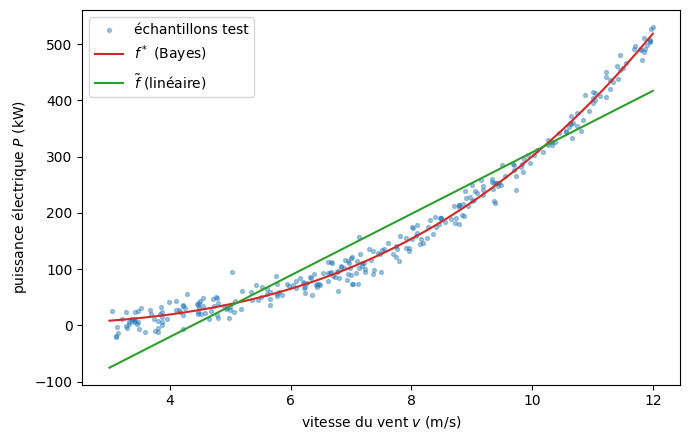

In [11]:
# nuage de test, prédicteur de Bayes (cubique, rouge) et estimateur linéaire (vert)
v_plot = np.linspace(V_MIN, V_MAX, 200)
plt.figure(figsize=(7, 4.5))
plt.scatter(x_test[:300], y_test[:300], s=8, alpha=0.4, label="échantillons test")
plt.plot(v_plot, bayes_predictor(v_plot), color="tab:red", label="$f^*$ (Bayes)")
plt.plot(
    v_plot,
    slope * v_plot + intercept,
    color="tab:green",
    label=r"$\tilde{f}$ (linéaire)",
)
plt.xlabel("vitesse du vent $v$ (m/s)")
plt.ylabel("puissance électrique $P$ (kW)")
plt.legend()
plt.tight_layout()
plt.show()


### Résultats :

| estimateur | risque empirique de test (kW²) |
|---|---|
| $f^{*}$ (Bayes) | 224.5 |
| $\tilde f$ (droite) | 1908.5 |
| risque de Bayes théorique $\sigma^{2}$ | 225 |

Les deux points sont confirmés. L'erreur de test de $f^*$ (224.5) est bien plus basse que celle de la droite (1908.5), et elle tombe quasiment sur le risque de Bayes théorique. Le petit écart de 0.5 avec 225 n'est que du bruit d'estimation Monte-Carlo : avec $10^6$ points de test, l'écart-type attendu sur cette moyenne est de l'ordre de $\sigma^2\sqrt{2/n_{\text{test}}} \approx 0.3$ kW², donc tout colle.

L'énorme écart de la droite, lui, correspond très exactement au terme $\mathbb{E}[(f^{*}(X)-\tilde f(X))^{2}]$ de la décomposition : une droite ne peut pas suivre une courbe cubique sur $[3,12]$, et ce biais se retrouve tel quel dans l'erreur de généralisation.


## Conclusion :

Le calcul théorique (question 1) et la vérification numérique (question 2) concordent : la simulation retrouve à la fois la forme du prédicteur de Bayes (f\* nettement meilleur que la droite) et la valeur du risque de Bayes (erreur de test de f\* ≈ σ²). Le cadre est donc cohérent de bout en bout.